# 02 — Manifold · Griffiths et al. 2021 (Breast Cancer)

Gate 1 = GO. Fit the cell-state manifold. Topology (curve vs tree) is read from the embedding and confirmed numerically: a PPT tree over-forks a strip into spurious micro-branches (forks grow with node count), while a principal **curve** fits cleanly (2 tips, 0 forks). Root at the Gast/pSom-high developmental origin. The principal-curve **edges are rendered on the manifold** so folds are visible directly (not inferred from a metric built on the same embedding).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr
name=os.path.split(os.getcwd())[1]
pth=os.path.join('..','..','..','..','..','..')
pth_in=os.path.join(pth,'data','cancer','vertebrate','CCCA','Claude','Breast',name)
pth_feat=os.path.join(pth,'data','features','biomart')
pth_fig=os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude','Breast',name)
os.makedirs(os.path.join(pth_fig,'colorbars'),exist_ok=True)

In [1]:
adata=sc.read_h5ad(os.path.join(pth_in,'processed.h5ad')); adata

### Score embryonic modules (for rooting; full signature step is notebook 03)
`score_genes` with the union control pool, on the full log1p matrix in `.raw`.

In [1]:
raw=adata.raw.to_adata(); raw.obsm=adata.obsm; raw.obs=adata.obs.copy()
feat={f:pd.read_csv(os.path.join(pth_feat,f+'.csv')).hsapiens.dropna().drop_duplicates() for f in ['GSE162534','GSE229103','rRNAModifications','union']}
gref=feat['union'][feat['union'].isin(raw.var_names)]
for src,nm in {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}.items():
    g=feat[src][feat[src].isin(raw.var_names)]
    sc.tl.score_genes(raw,gene_list=g,score_name=nm,ctrl_as_ref=False,gene_pool=gref,random_state=1234)
    adata.obs[nm]=raw.obs[nm].values
print('module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

module means: {'Gast': -0.0215, 'pSom': -0.0519, 'Crest': 0.0212}


### Topology test — tree vs curve, read from the embedding
PPT tree forks proliferate with node count (spurious); principal curve is 2 tips / 0 forks -> **linear**.

In [1]:
for N in [15,20,30]:
    a=adata.copy(); scf.tl.tree(a,method='ppt',Nodes=N,ppt_lambda=2000,ppt_sigma=0.5,use_rep='X_umap',seed=1,ppt_nsteps=200)
    deg=np.asarray(a.uns['graph']['B'].sum(0)).ravel()
    print(f'PPT Nodes={N}: tips={int((deg==1).sum())} forks={int((deg>=3).sum())}')

inferring a principal tree --> parameters used 
    15 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:   8%|8         | 16/200 [00:01<00:16, 11.06it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
PPT Nodes=15: tips=6 forks=4
inferring a principal tree --> parameters used 
    20 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:   8%|8         | 16/200 [00:00<00:05, 33.11it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in represe

In [1]:
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', seed=1)
B=adata.uns['graph']['B']; F=adata.uns['graph']['F']; deg=np.asarray(B.sum(0)).ravel()
print('CURVE Nodes=20: tips',int((deg==1).sum()),'forks',int((deg>=3).sum()))

inferring a principal curve --> parameters used 
    20 principal points, mu = 0.1, lambda = 0.01
    finished (0:00:11) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
CURVE Nodes=20: tips 2 forks 0


### Root at the Gast/pSom-high, Crest-low tip (developmental origin — NOT the Crest tip, NOT a proliferation state)

In [1]:
tips=np.where(deg==1)[0]
nn=NearestNeighbors(n_neighbors=1).fit(F.T); _,cn=nn.kneighbors(adata.obsm['X_umap']); cn=cn.ravel()
score={}
for t in tips:
    m=cn==t; score[t]=adata.obs.Gast[m].mean()+adata.obs.pSom[m].mean()-adata.obs.Crest[m].mean()
    print('tip',t,'n',int(m.sum()),'Gast',round(adata.obs.Gast[m].mean(),3),'pSom',round(adata.obs.pSom[m].mean(),3),'Crest',round(adata.obs.Crest[m].mean(),3))
root=int(max(score,key=score.get)); print('ROOT node =',root)
scf.tl.root(adata, root)
scf.tl.pseudotime(adata, n_jobs=8, seed=1)

tip 0 n 7889 Gast -0.019 pSom -0.055 Crest 0.023
tip 2 n 5087 Gast -0.035 pSom -0.029 Crest 0.011
ROOT node = 2
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:02:12) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [1]:
for nm in ['Gast','pSom','Crest']:
    print('pseudotime rho',nm, round(spearmanr(adata.obs.t,adata.obs[nm]).correlation,3))
scf.tl.rename_milestones(adata, new={str(k):v for k,v in zip(sorted(set(adata.obs.milestones.astype(str))),['Origin','Terminus'][:len(set(adata.obs.milestones))])}) if 'milestones' in adata.obs else None

pseudotime rho Gast 0.019
pseudotime rho pSom -0.116
pseudotime rho Crest 0.083


**Note (feeds Gate 2 / notebook 03):** signatures barely track pseudotime here (|rho| <= 0.22) — the fitted trajectory follows the dominant ribosomal/housekeeping geometry, not the embryonic axis. This weak pseudotime->signature coupling is the first sign the embryonic pattern does not organise this manifold.

In [1]:
# ElPiGraph leaves a ragged 'epg' dict in .uns that h5ad cannot serialise; drop it (curve graph B/F/root kept)
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in,'manifold.h5ad')); print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (102179, 15645)


### manifold.pdf — pseudotime with the ACTUAL principal-curve edges drawn (fold check)
The curve is a single connected path in the ONE original embedding (no re-embedding of the compartment), so a reviewer can see it is fold-free/seam-free directly.

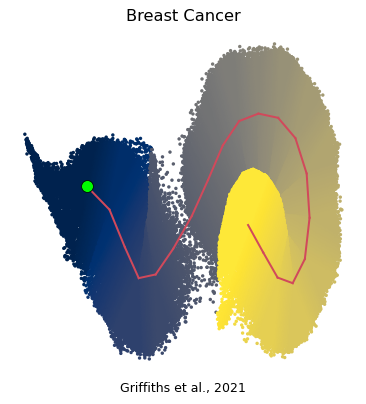

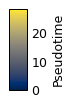

In [1]:
root=adata.uns['graph']['root']
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,color='t',cmap='cividis',size=30,colorbar_loc=None,frameon=False,show=False,ax=ax)
for i in range(B.shape[0]):
    for j in range(i+1,B.shape[1]):
        if B[i,j]>0: ax.plot([F[0,i],F[0,j]],[F[1,i],F[1,j]],'-',color='#d1495b',lw=1.6,zorder=10)
ax.scatter(F[0,root],F[1,root],c='lime',s=90,edgecolor='k',lw=.6,zorder=11)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Breast Cancer', size=13)
ax.text(.5,-.05,'Griffiths et al., 2021',ha='center',transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
fig2=plt.figure(figsize=(.66,1)); cax=fig2.add_axes([.35,.05,.3,.9])
sm=plt.cm.ScalarMappable(cmap='cividis',norm=plt.Normalize(adata.obs.t.min(),adata.obs.t.max()))
cb=plt.colorbar(sm,cax=cax); cb.set_label('Pseudotime'); cb.ax.tick_params(size=0)
fig2.savefig(os.path.join(pth_fig,'colorbars','t_colorbar.pdf'), bbox_inches='tight')